# Inteligencia Artificial — Tarea 3 (Puntos 1 y 2)

**Integrantes:** Laura Ruidiaz y Angelo Maiale

**Contenido**
1. Kernel cuadrático
2. SVC con kernel gaussiano
   - 2.0 Dataset y justificación de los requisitos
   - 2.1 Análisis exploratorio y limpieza
   - 2.2 Separación del conjunto de prueba
   - 2.3 SVC con 2 features: efecto de gamma y C
   - 2.4 Pipeline + GridSearchCV
   - 2.5 Mapa de calor
   - 2.6 Score final en prueba

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

SEMILLA = 42  # semilla fija: los resultados son reproducibles

---
# 1. Kernel cuadrático (3 puntos)

Kernel: $K(\boldsymbol{x},\boldsymbol{z}) = (\boldsymbol{x}^T\boldsymbol{z} + c)^2 = \phi(\boldsymbol{x})^T\phi(\boldsymbol{z})$, con $c = 9$ y $\boldsymbol{x},\boldsymbol{z}\in\mathbb{R}^2$.

### Construcción de $\phi$ (sirve para cualquier $d$)
Desarrollando el cuadrado:

$$
(\boldsymbol{x}^T\boldsymbol{z} + c)^2 = \Big(\sum_i x_i z_i + c\Big)^2
= \underbrace{\sum_{i}\sum_{j} (x_i x_j)(z_i z_j)}_{\text{cuadráticos}}
+ \underbrace{\sum_i (\sqrt{2c}\,x_i)(\sqrt{2c}\,z_i)}_{\text{lineales}}
+ \underbrace{c\cdot c}_{\text{constante}}
$$

Cada término es "algo de $\boldsymbol{x}$" por "lo mismo de $\boldsymbol{z}$", así que:

$$
\phi(\boldsymbol{x}) = \big[\,x_i x_j \ (\forall i,j),\ \ \sqrt{2c}\,x_i\ (\forall i),\ \ c\,\big]
$$

Para $d=2$: $\phi(\boldsymbol{x}) = [x_1x_1,\ x_1x_2,\ x_2x_1,\ x_2x_2,\ \sqrt{2c}\,x_1,\ \sqrt{2c}\,x_2,\ c]$

> Versión compacta equivalente: como $x_1x_2 = x_2x_1$, se pueden juntar en un solo término $\sqrt{2}\,x_1x_2$. El producto punto da lo mismo.

In [2]:
c = 9

def phi(x, c=c):
    # Transformación phi para un vector de cualquier tamaño d -> d^2 + d + 1 componentes
    x = np.asarray(x, dtype=float)
    cuadraticos = np.outer(x, x).ravel()   # x_i * x_j para todo i, j   (d^2)
    lineales = np.sqrt(2 * c) * x          # sqrt(2c) * x_i             (d)
    return np.concatenate([cuadraticos, lineales, [c]])   # + constante c (1)

def phi_compacta(x, c=c):
    # Sin términos repetidos: x_i^2, sqrt(2) x_i x_j (i<j), sqrt(2c) x_i, c -> (d+1)(d+2)/2 componentes
    x = np.asarray(x, dtype=float)
    d = len(x)
    cruzados = [np.sqrt(2) * x[i] * x[j] for i in range(d) for j in range(i + 1, d)]
    return np.concatenate([x**2, cruzados, np.sqrt(2 * c) * x, [c]])

def K(x, z, c=c):
    # El kernel: un producto punto en R^d, una suma y un cuadrado
    return (np.dot(x, z) + c) ** 2

### 1a) $\phi([2,-3]^T)$
Con $\sqrt{2c} = \sqrt{18} \approx 4.2426$:

$\phi(\boldsymbol{x}) = [4,\ -6,\ -6,\ 9,\ 2\sqrt{18},\ -3\sqrt{18},\ 9] \approx [4,\ -6,\ -6,\ 9,\ 8.485,\ -12.728,\ 9]$

In [3]:
x = np.array([2, -3])
print("phi(x)          =", np.round(phi(x), 4))
print("phi_compacta(x) =", np.round(phi_compacta(x), 4))

phi(x)          = [  4.      -6.      -6.       9.       8.4853 -12.7279   9.    ]
phi_compacta(x) = [  4.       9.      -8.4853   8.4853 -12.7279   9.    ]


### 1b) Verificación con $\boldsymbol{z} = [1,4]^T$
- Con el kernel: $\boldsymbol{x}^T\boldsymbol{z} = 2\cdot1 + (-3)\cdot4 = -10 \Rightarrow K = (-10+9)^2 = 1$
- Con $\phi$: $4\cdot1 + (-6)\cdot4 + (-6)\cdot4 + 9\cdot16 + 18\cdot(2\cdot1) + 18\cdot(-3\cdot4) + 9\cdot9 = 4-24-24+144+36-216+81 = 1$ ✔

In [4]:
z = np.array([1, 4])
print("phi(z)          =", np.round(phi(z), 4))
print("phi(x)^T phi(z) =", round(phi(x) @ phi(z), 6))
print("K(x, z)         =", K(x, z))
print("¿Coinciden?     ", np.isclose(phi(x) @ phi(z), K(x, z)))

# phi funciona para cualquier tamaño de vector (prueba con d = 5 al azar)
rng = np.random.default_rng(0)
a, b = rng.normal(size=5), rng.normal(size=5)
print("\nd = 5 al azar -> phi(a)^T phi(b) =", round(phi(a) @ phi(b), 6), "| K(a, b) =", round(K(a, b), 6))

phi(z)          = [ 1.      4.      4.     16.      4.2426 16.9706  9.    ]
phi(x)^T phi(z) = 1.0
K(x, z)         = 1
¿Coinciden?      True

d = 5 al azar -> phi(a)^T phi(b) = 101.682143 | K(a, b) = 101.682143


### 1c) Componentes y costo para $d$ features

| | Cantidad | Orden |
|---|---|---|
| Componentes de $\phi(\boldsymbol{x})$ | $d^2 + d + 1$ (compacta: $\frac{(d+1)(d+2)}{2}$) | $O(d^2)$ |
| Calcular $\phi(\boldsymbol{x})^T\phi(\boldsymbol{z})$ directamente | construir $\phi$ y sumar $\sim d^2$ productos | $O(d^2)$ |
| Calcular $K(\boldsymbol{x},\boldsymbol{z})$ | un producto punto de $d$ términos + suma + cuadrado | $O(d)$ |

**¿Por qué son útiles los kernels?** Obtenemos el producto punto en el espacio grande de $\phi$ (donde los datos pueden ser separables por un hiperplano) **pagando solo el costo de $\mathbb{R}^d$**. La SVM solo necesita productos punto entre ejemplos, así que nunca hay que construir $\phi$. Con el kernel gaussiano $\phi$ tiene incluso infinitas dimensiones y aun así $K$ se calcula en $O(d)$.

In [5]:
print(f"{'d':>6} {'componentes phi':>16} {'oper. phi^T phi':>16} {'oper. K':>9}")
for d in [2, 10, 100, 1000]:
    print(f"{d:>6} {d**2 + d + 1:>16} {'~' + str(d**2 + d + 1):>16} {'~' + str(d):>9}")

     d  componentes phi  oper. phi^T phi   oper. K
     2                7               ~7        ~2
    10              111             ~111       ~10
   100            10101           ~10101      ~100
  1000          1001001         ~1001001     ~1000


---
# 2. SVC con kernel gaussiano (7 puntos)

## 2.0 Dataset: *Rice Dataset Commeo and Osmancik*

- **Kaggle:** https://www.kaggle.com/datasets/muratkokludataset/rice-dataset-commeo-and-osmancik
- **Fuente original:** Cinar, I. y Koklu, M. (2019). *Classification of Rice Varieties Using Artificial Intelligence Methods*. IJISAE, 7(3), 188-194. (también en el UCI ML Repository, id 545). Licencia CC0.
- **Archivo usado:** `Rice_Cammeo_Osmancik.csv` (se entrega junto con este notebook).

Se fotografiaron 3810 granos de arroz de dos variedades turcas (**Cammeo** y **Osmancik**) y con procesamiento de imágenes se midieron 7 características morfológicas de cada grano.

### Cumplimiento de los requisitos de la tarea

| Requisito | Pedido | Este dataset | ¿Cumple? |
|---|---|---|---|
| Datos reales | Sí | Fotografías reales de granos de arroz | ✅ |
| Nº de ejemplos | entre 1000 y 10 000 | **3810** (no hace falta muestrear) | ✅ |
| Nº de features cuantitativas | entre 5 y 10 | **7**, todas numéricas continuas | ✅ |
| Sin variables indicadoras | Sí | Ninguna feature es 0/1 ni categórica | ✅ |
| Etiqueta categórica | Sí | `Class`: Cammeo / Osmancik | ✅ |
| Distinto a tareas y laboratorios | Sí | No es Iris, Titanic, MNIST, etc. | ✅ |

### ¿Qué mide cada feature? (en píxeles de la foto)

| Feature | Qué mide |
|---|---|
| `Area` | Número de píxeles dentro del grano → **tamaño** |
| `Perimeter` | Longitud del borde del grano |
| `Major_Axis_Length` | **Largo** del grano (eje mayor de la elipse que mejor lo aproxima) |
| `Minor_Axis_Length` | **Ancho** del grano (eje menor de esa elipse) |
| `Eccentricity` | Qué tan **alargado** es: 0 = círculo, cerca de 1 = muy alargado |
| `Convex_Area` | Píxeles del menor polígono convexo que contiene al grano |
| `Extent` | Área del grano / área del rectángulo que lo encierra (cuánto "llena" su caja) |

## 2.1 Análisis exploratorio

In [6]:
df = pd.read_csv("Rice_Cammeo_Osmancik.csv")
FEATURES = ["Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length",
            "Eccentricity", "Convex_Area", "Extent"]
ETIQUETA = "Class"

print("Filas, columnas:", df.shape)
print(df.dtypes)
df.head()

Filas, columnas: (3810, 8)
Area                   int64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area            int64
Extent               float64
Class                    str
dtype: object


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


In [7]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,3810.0,12667.728,1732.368,7551.000,11370.500,12421.500,13950.000,18913.000
Perimeter,3810.0,454.239,35.597,359.100,426.145,448.852,483.684,548.446
Major_Axis_Length,3810.0,188.776,17.449,145.264,174.354,185.810,203.550,239.010
Minor_Axis_Length,3810.0,86.314,5.730,59.532,82.732,86.435,90.144,107.542
Eccentricity,3810.0,0.887,0.021,0.777,0.872,0.889,0.903,0.948
Convex_Area,3810.0,12952.497,1776.972,7723.000,11626.250,12706.500,14284.000,19099.000
Extent,3810.0,0.662,0.077,0.497,0.599,0.645,0.727,0.861


Las escalas son muy distintas: `Area` está en miles y `Eccentricity`/`Extent` entre 0 y 1. El kernel gaussiano usa distancias $\|\boldsymbol{x}-\boldsymbol{z}\|^2$, así que **sin estandarizar `Area` dominaría la distancia** y las demás features casi no influirían.

### Proporción de cada clase

,cantidad,proporción
Class,,
Osmancik,2180,0.572
Cammeo,1630,0.428


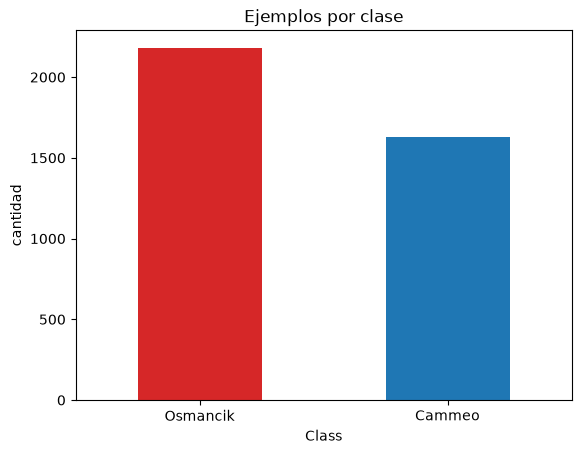

In [8]:
conteo = df[ETIQUETA].value_counts()
proporcion = df[ETIQUETA].value_counts(normalize=True)
display(pd.DataFrame({"cantidad": conteo, "proporción": proporcion.round(3)}))

conteo.plot.bar(color=["tab:red", "tab:blue"], rot=0, title="Ejemplos por clase")
plt.ylabel("cantidad")
plt.show()

**~57 % Osmancik y ~43 % Cammeo**: hay un leve desbalance, no extremo. Un modelo que siempre dijera "Osmancik" tendría 57 % de exactitud: **esa es la línea base** a superar.

### Distribución de las features por clase
Si los histogramas de las dos clases están separados, esa feature ayuda a distinguirlas.

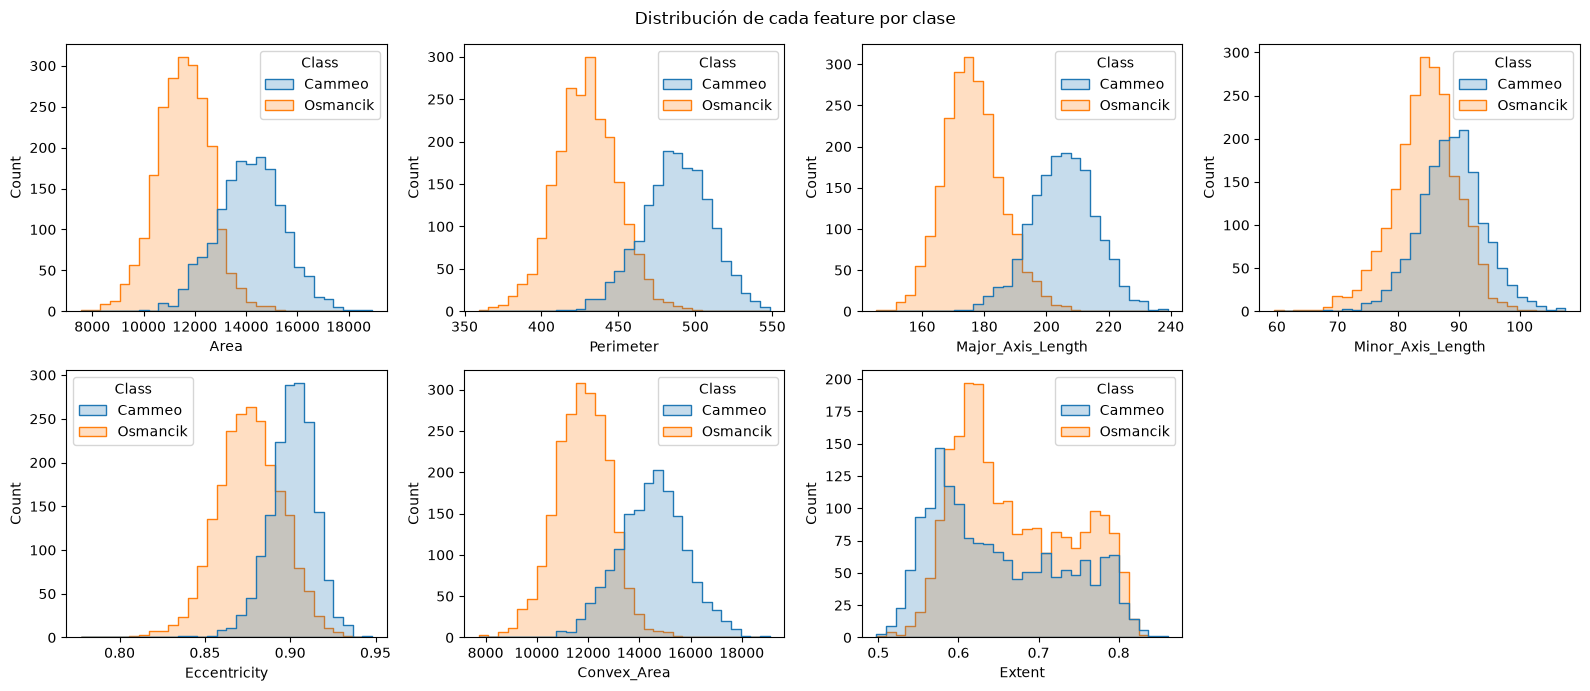

In [9]:
fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
for eje, feature in zip(ejes.ravel(), FEATURES):
    sns.histplot(data=df, x=feature, hue=ETIQUETA, ax=eje, bins=30, element="step")
ejes.ravel()[-1].axis("off")
fig.suptitle("Distribución de cada feature por clase")
fig.tight_layout()
plt.show()

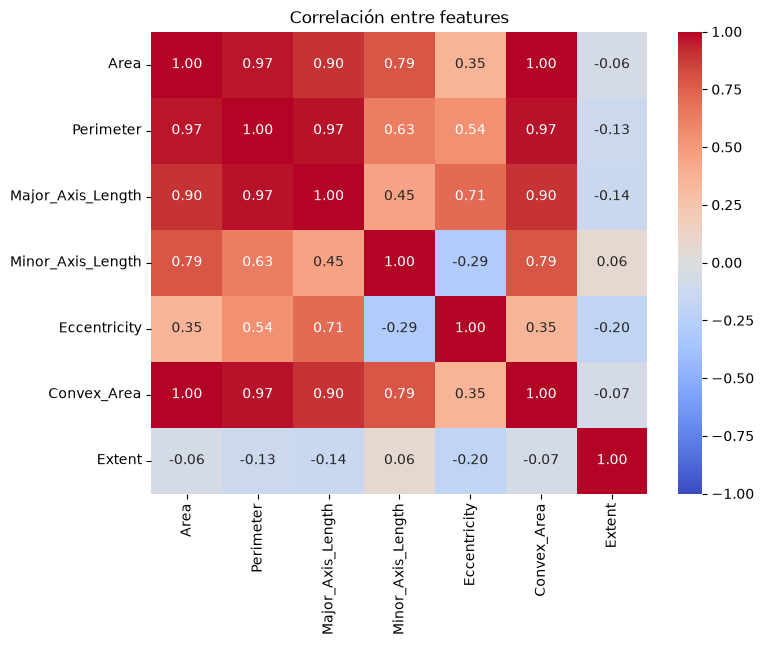

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre features")
plt.show()

**Observaciones:**
- Los granos **Cammeo son más grandes y más largos** (mayor `Area`, `Perimeter`, `Major_Axis_Length`). `Extent` casi no separa las clases.
- `Area`, `Perimeter` y `Convex_Area` están casi perfectamente correlacionadas (≈ 0.97–1.0): las tres miden el tamaño del grano.

### Limpieza de datos
Revisamos: valores faltantes, filas duplicadas, espacios en la etiqueta y valores físicamente imposibles (medidas ≤ 0, `Eccentricity` o `Extent` fuera de [0, 1], o área mayor que el área convexa).

In [11]:
n_inicial = len(df)
df[ETIQUETA] = df[ETIQUETA].str.strip()          # quitar espacios en la etiqueta

print("Valores faltantes por columna:\n", df.isna().sum(), "\n")
df = df.dropna()

print("Filas duplicadas:", df.duplicated().sum())
df = df.drop_duplicates()

positivas = ["Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length", "Convex_Area"]
validas = ((df[positivas] > 0).all(axis=1)
           & df["Eccentricity"].between(0, 1)
           & df["Extent"].between(0, 1)
           & (df["Area"] <= df["Convex_Area"]))
print("Filas con valores imposibles:", (~validas).sum())
df = df[validas].reset_index(drop=True)

print(f"\nFilas: {n_inicial} -> {len(df)}")

Valores faltantes por columna:
 Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64 

Filas duplicadas: 0
Filas con valores imposibles: 0

Filas: 3810 -> 3810


El dataset viene limpio: no hay faltantes, duplicados ni valores imposibles, así que no se elimina ninguna fila. Los valores extremos que se ven en los histogramas son granos reales (más grandes o más pequeños) y se mantienen.

## 2.2 Separación del conjunto de prueba
Se aparta el **20 %** como conjunto de prueba. `stratify=y` mantiene la proporción de clases en ambos conjuntos. **La prueba no se usa hasta el final** (sección 2.6), para que su score sea una estimación honesta de cómo funciona el modelo con datos nuevos.

In [12]:
X = df[FEATURES]
y = df[ETIQUETA]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Proporción en entrenamiento:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Proporción en prueba:       ", y_test.value_counts(normalize=True).round(3).to_dict())

Entrenamiento: (3048, 7) | Prueba: (762, 7)
Proporción en entrenamiento: {'Osmancik': 0.572, 'Cammeo': 0.428}
Proporción en prueba:        {'Osmancik': 0.572, 'Cammeo': 0.428}


## 2.3 SVC con 2 features: efecto de gamma y C

Usamos **`Major_Axis_Length` (largo)** y **`Minor_Axis_Length` (ancho)** del grano: son fáciles de interpretar y separan bien las clases.

Del conjunto de entrenamiento apartamos un **25 % de validación** para comparar los modelos sin tocar la prueba. El `StandardScaler` se ajusta **solo** con los datos de entrenamiento.

**Recordatorio de teoría**
- Kernel gaussiano: $K(\boldsymbol{x},\boldsymbol{z}) = \exp(-\gamma\|\boldsymbol{x}-\boldsymbol{z}\|^2)$, con $\gamma = \dfrac{1}{2\sigma^2}$. $\gamma$ grande ⇔ $\sigma$ chico ⇔ cada punto influye solo muy cerca de sí.
- SVM de margen suave: $\min \frac{1}{2}\|\boldsymbol{w}\|^2 + C\sum_i \xi_i$. Las holguras $\xi_i$ miden cuánto viola cada ejemplo el margen; $C$ es el "precio" de esas violaciones.

In [13]:
F1, F2 = "Major_Axis_Length", "Minor_Axis_Length"

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train[[F1, F2]], y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

escalador = StandardScaler().fit(X_tr)          # se ajusta SOLO con entrenamiento
X_tr_s, X_val_s = escalador.transform(X_tr), escalador.transform(X_val)
y_tr, y_val = y_tr.to_numpy(), y_val.to_numpy()
print("Entrenamiento:", X_tr_s.shape, "| Validación:", X_val_s.shape)

Entrenamiento: (2286, 2) | Validación: (762, 2)


In [14]:
def graficar_frontera(modelo, X, y, titulo, eje):
    # Regiones de cada clase (fondo), frontera (línea continua, f(x)=0),
    # márgenes (punteadas, f(x)=±1), puntos y vectores de soporte (círculos negros).
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = modelo.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    eje.contourf(xx, yy, Z > 0, alpha=0.25, cmap="coolwarm")
    eje.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=1)
    eje.scatter(X[:, 0], X[:, 1], c=(y == modelo.classes_[1]), cmap="coolwarm", s=8, alpha=0.6)
    sv = modelo.support_vectors_
    eje.scatter(sv[:, 0], sv[:, 1], s=30, facecolors="none", edgecolors="k", linewidths=0.6)
    eje.set_title(titulo, fontsize=10)
    eje.set_xlabel(F1 + " (estandarizada)")
    eje.set_ylabel(F2 + " (estandarizada)")

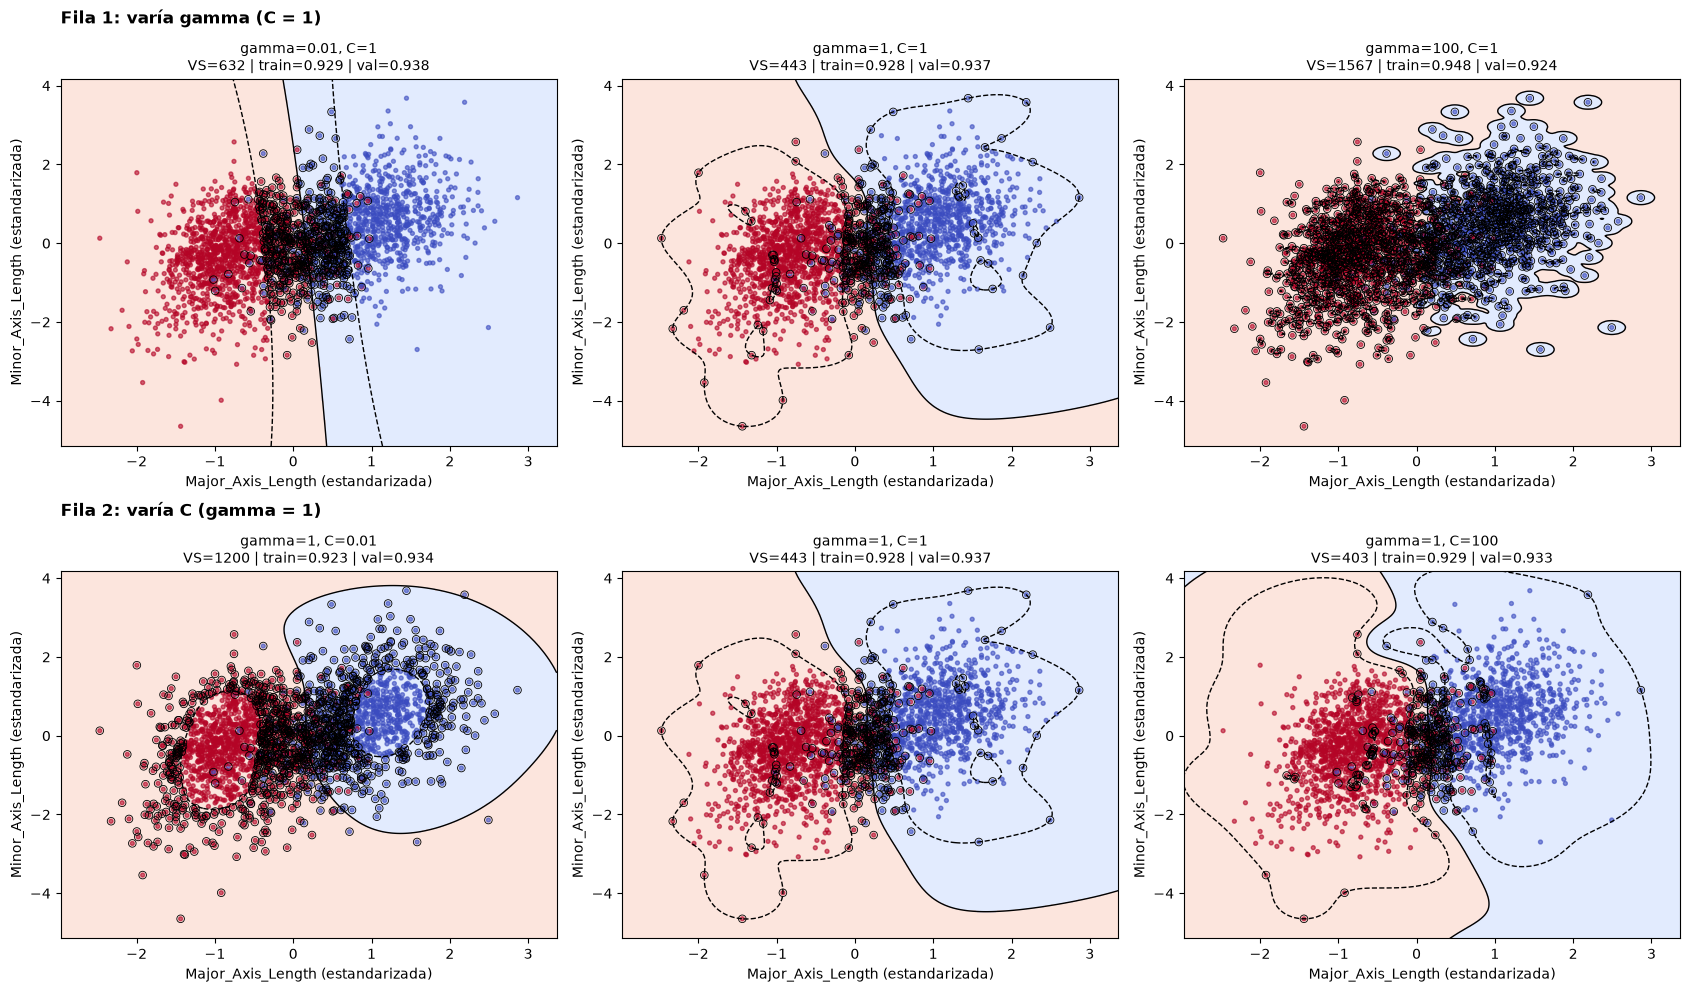

Rojo = Osmancik, azul = Cammeo. Círculos negros = vectores de soporte.


,gamma,C,vectores de soporte,exactitud entrenamiento,exactitud validación
0,0.01,1.00,632,0.9291,0.9383
1,1.00,1.00,443,0.9283,0.9370
2,100.00,1.00,1567,0.9479,0.9239
3,1.00,0.01,1200,0.9234,0.9344
4,1.00,1.00,443,0.9283,0.9370
5,1.00,100.00,403,0.9291,0.9331


In [15]:
configuraciones = [
    {"gamma": 0.01, "C": 1}, {"gamma": 1, "C": 1},    {"gamma": 100, "C": 1},    # varía gamma
    {"gamma": 1, "C": 0.01}, {"gamma": 1, "C": 1},    {"gamma": 1,   "C": 100},  # varía C
]

fig, ejes = plt.subplots(2, 3, figsize=(17, 10))
resultados = []
for cfg, eje in zip(configuraciones, ejes.ravel()):
    modelo = SVC(kernel="rbf", gamma=cfg["gamma"], C=cfg["C"]).fit(X_tr_s, y_tr)
    n_sv = int(modelo.n_support_.sum())
    acc_tr, acc_val = modelo.score(X_tr_s, y_tr), modelo.score(X_val_s, y_val)
    resultados.append({**cfg, "vectores de soporte": n_sv,
                       "exactitud entrenamiento": round(acc_tr, 4),
                       "exactitud validación": round(acc_val, 4)})
    graficar_frontera(modelo, X_tr_s, y_tr,
                      f"gamma={cfg['gamma']}, C={cfg['C']}\nVS={n_sv} | train={acc_tr:.3f} | val={acc_val:.3f}", eje)

ejes[0, 0].annotate("Fila 1: varía gamma (C = 1)", (0, 1.15), xycoords="axes fraction", fontsize=12, weight="bold")
ejes[1, 0].annotate("Fila 2: varía C (gamma = 1)", (0, 1.15), xycoords="axes fraction", fontsize=12, weight="bold")
fig.tight_layout()
plt.show()
print(f"Rojo = {modelo.classes_[1]}, azul = {modelo.classes_[0]}. Círculos negros = vectores de soporte.")
pd.DataFrame(resultados)

### ¿Cómo cambia la frontera?

**Con gamma (fila 1, C = 1):**
- **gamma = 0.01** (σ grande): cada punto influye lejos → frontera **casi recta** y márgenes anchos. Modelo simple.
- **gamma = 1**: frontera **suavemente curva**. Buen equilibrio.
- **gamma = 100** (σ muy chico): cada punto influye solo a su alrededor → aparecen **"islas"** alrededor de puntos individuales. La exactitud de entrenamiento sube (≈ 0.95) pero la de validación **baja** (≈ 0.92) y casi todos los puntos son vectores de soporte: esto es **overfitting** (el modelo memoriza el entrenamiento).

**Con C (fila 2, gamma = 1):**
- **C = 0.01**: violar el margen es barato (las holguras $\xi_i$ casi no se penalizan) → **margen muy ancho** y muchísimos vectores de soporte (≈ 1200): todos los puntos dentro del margen o mal clasificados lo son. Modelo más "rígido".
- **C = 1**: margen intermedio.
- **C = 100**: violar el margen es caro → **margen angosto**, menos vectores de soporte (≈ 400) y la frontera se curva más para clasificar bien los puntos de entrenamiento (riesgo de overfitting).

Las dos clases se solapan en la zona central (granos de tamaño intermedio), por eso ningún modelo supera ≈ 94 % con solo estas 2 features.

## 2.4 Pipeline + GridSearchCV (con las 7 features)

- **Pipeline** = `StandardScaler` → `SVC(kernel="rbf")`.
- **¿Por qué el scaler va dentro del Pipeline?** GridSearchCV hace validación cruzada: en cada fold el scaler se ajusta **solo con la parte de entrenamiento de ese fold**. Si estandarizáramos antes con todos los datos, la media y la desviación incluirían información del fold de validación (**fuga de datos**) y el score sería demasiado optimista.
- **Grilla logarítmica**: C ∈ {10⁻², …, 10⁴} (7 valores) y gamma ∈ {10⁻⁴, …, 10¹} (6 valores). Usamos escala logarítmica porque lo que importa es el orden de magnitud.
- **Validación cruzada de 5 folds** (estratificada) ⇒ se entrenan 7 × 6 × 5 = **210 modelos + 1** reentrenamiento final del mejor con todo el conjunto de entrenamiento.

In [16]:
pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("svc", SVC(kernel="rbf")),
])

grilla = {
    "svc__C": np.logspace(-2, 4, 7),      # 0.01, 0.1, 1, 10, 100, 1000, 10000
    "svc__gamma": np.logspace(-4, 1, 6),  # 0.0001, 0.001, 0.01, 0.1, 1, 10
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busqueda = GridSearchCV(pipeline, grilla, cv=cv, scoring="accuracy", n_jobs=-1)
busqueda.fit(X_train, y_train)

n_comb = len(grilla["svc__C"]) * len(grilla["svc__gamma"])
print(f"Modelos entrenados: {n_comb} combinaciones x 5 folds + 1 = {n_comb * 5 + 1}")
print("Mejores hiperparámetros:", {k: float(v) for k, v in busqueda.best_params_.items()})
print(f"best_score_ (exactitud media en validación cruzada): {busqueda.best_score_:.4f}")

Modelos entrenados: 42 combinaciones x 5 folds + 1 = 211
Mejores hiperparámetros: {'svc__C': 1000.0, 'svc__gamma': 0.001}
best_score_ (exactitud media en validación cruzada): 0.9347


`best_score_` es el **promedio de la exactitud en los 5 folds de validación** para la mejor combinación. Se calcula con datos de entrenamiento y se usó para *elegir* los hiperparámetros, por eso es algo optimista y **no reemplaza al score de prueba**.

## 2.5 Mapa de calor del score de validación cruzada

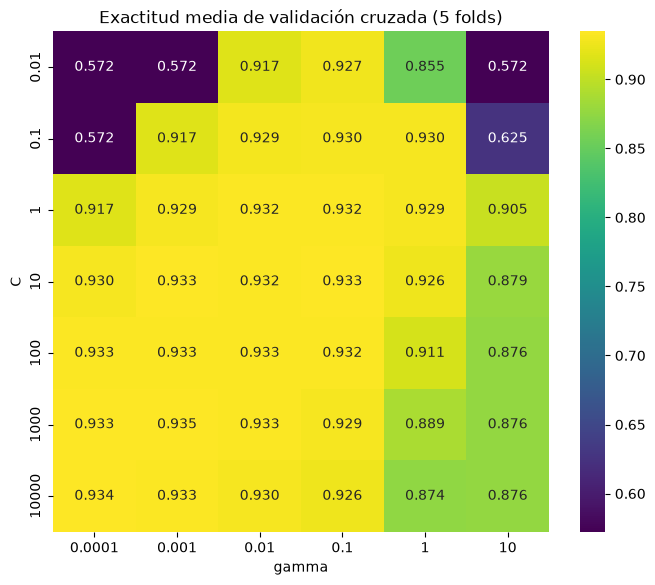

In [17]:
res = pd.DataFrame(busqueda.cv_results_)
tabla = res.pivot_table(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")

plt.figure(figsize=(8, 6.5))
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="viridis",
            xticklabels=[f"{g:g}" for g in tabla.columns],
            yticklabels=[f"{c:g}" for c in tabla.index])
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Exactitud media de validación cruzada (5 folds)")
plt.show()

**Lectura del mapa de calor:**
- **Esquina superior izquierda (C y gamma chicos)**: ≈ 0.572 = proporción de Osmancik. El modelo es tan simple que predice siempre la clase mayoritaria (**underfitting**).
- **Columna gamma = 10**: el score cae (≈ 0.88) aunque C sea grande. Con gamma grande la frontera se ajusta a cada punto: **overfitting** (igual que las "islas" de la sección 2.3).
- **Zona amarilla (diagonal central)**: muchas combinaciones dan ≈ 0.93. Cuando gamma baja, hace falta un C más grande para compensar, por eso la zona buena va en diagonal.

## 2.6 Score del mejor modelo en el conjunto de prueba (una sola vez)
`busqueda.best_estimator_` ya está reentrenado con todo `X_train`. Ahora, y solo ahora, usamos el conjunto de prueba.

In [18]:
mejor_modelo = busqueda.best_estimator_
score_prueba = mejor_modelo.score(X_test, y_test)
print(f"Exactitud en PRUEBA: {score_prueba:.4f}")
print(f"(best_score_ en validación cruzada fue {busqueda.best_score_:.4f})")

Exactitud en PRUEBA: 0.9173
(best_score_ en validación cruzada fue 0.9347)


**Conclusión:** el SVC con kernel gaussiano clasifica correctamente ≈ 92 % de los granos de prueba, muy por encima de la línea base de 57 %. El score de prueba es un poco menor que `best_score_`, lo esperable: `best_score_` se usó para elegir los hiperparámetros, mientras que la prueba son datos que el modelo nunca vio.

---
# 3. Árbol de decisión y random forest (6 puntos)

Se usan **los mismos datos y la misma separación de prueba** del punto 2 (`X_train`, `X_test`, `y_train`, `y_test`) y la **misma validación cruzada** (`cv`, 5 folds estratificados).

> Los árboles **no necesitan estandarizar** las features: cada nodo compara *una sola* feature con un umbral, y eso no depende de la escala. Por eso aquí no hay `StandardScaler`, a diferencia del SVC.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

## 3.1 Árbol de decisión: escoger `max_depth` con GridSearchCV
Probamos `max_depth` de 1 a 20. Con 5 folds se entrenan 20 × 5 = 100 modelos + 1 reentrenamiento final = **101**. Pedimos también el score de entrenamiento (`return_train_score=True`) para ver el overfitting: un árbol muy profundo memoriza el entrenamiento.

In [ ]:
busqueda_arbol = GridSearchCV(
    DecisionTreeClassifier(random_state=SEMILLA),
    {"max_depth": list(range(1, 21))},
    cv=cv, scoring="accuracy", n_jobs=-1, return_train_score=True)
busqueda_arbol.fit(X_train, y_train)

print("Modelos entrenados: 20 profundidades x 5 folds + 1 =", 20 * 5 + 1)
print("Mejor max_depth:", busqueda_arbol.best_params_["max_depth"])
print(f"best_score_ (exactitud media de validación cruzada): {busqueda_arbol.best_score_:.4f}")

res_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
plt.figure(figsize=(8, 5))
plt.plot(res_arbol["param_max_depth"], res_arbol["mean_train_score"], "o-", label="entrenamiento")
plt.plot(res_arbol["param_max_depth"], res_arbol["mean_test_score"], "s-", label="validación cruzada")
plt.axvline(busqueda_arbol.best_params_["max_depth"], color="gray", linestyle="--", label="mejor max_depth")
plt.xlabel("max_depth")
plt.ylabel("exactitud")
plt.title("Árbol de decisión: exactitud según la profundidad")
plt.legend()
plt.show()

res_arbol[["param_max_depth", "mean_train_score", "mean_test_score"]].head(6).round(4)

**Lectura de la curva (overfitting):**
- La exactitud de **entrenamiento sube siempre** con la profundidad (0.93 con `max_depth = 1` hasta ≈ 0.999 con 20): un árbol profundo tiene tantos cortes que memoriza cada grano.
- La exactitud de **validación baja** (0.927 → ≈ 0.89): los cortes extra se ajustan al ruido del entrenamiento y no generalizan. Esa brecha creciente entre las dos curvas es el **overfitting**.
- El mejor valor es **`max_depth = 1`** (un solo corte). La profundidad 2 da exactamente la misma validación (0.9272) y `GridSearchCV` se queda con la primera de las empatadas. Es coherente con lo que vimos antes: las dos clases se separan sobre todo por el **tamaño/largo del grano** y el resto del solapamiento no se arregla con más cortes.

## 3.2 Árbol de profundidad 3
Un árbol de profundidad 1 es muy poco para *dibujar*, así que (como pide la tarea) dibujamos uno de **profundidad 3**, con los nombres de las features y de las clases. Cada nodo muestra la pregunta, el `gini` (impureza), el nº de ejemplos (`samples`), cuántos hay de cada clase (`value`) y la clase mayoritaria (`class`).

In [ ]:
arbol3 = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(arbol3, feature_names=FEATURES, class_names=list(arbol3.classes_),
          filled=True, rounded=True, fontsize=10)
plt.title("Árbol de decisión de profundidad 3")
plt.show()

### Proceso de decisión que describe el árbol
Para clasificar un grano se baja desde la raíz respondiendo una pregunta por nodo hasta llegar a una **hoja**; la hoja devuelve la clase mayoritaria de los granos de entrenamiento que cayeron ahí.

1. **Raíz:** ¿`Major_Axis_Length` ≤ 192.17? (¿el grano es *corto*?). Es el corte que mejor separa las clases (el mismo que elige el árbol de profundidad 1).
2. **Rama "corto" (sí):** se sigue preguntando por `Major_Axis_Length` (≤ 186.51, y luego ≤ 181.24 o ≤ 189.51). **Todas las hojas de esta rama dicen Osmancik.** Cuanto más corto el grano, más pura la hoja: con `Major_Axis_Length` ≤ 181.24 hay 1270 Osmancik contra 12 Cammeo.
3. **Rama "largo" (no):** se pregunta por `Perimeter` ≤ 467.86.
   - **Perímetro grande** → ¿`Major_Axis_Length` ≤ 206.06? Si es mayor (granos muy largos): hoja de **644 Cammeo y 0 Osmancik**. Si no: **423 Cammeo contra 35 Osmancik**, también Cammeo.
   - **Perímetro chico** → ¿`Minor_Axis_Length` ≤ 88.66? Si sí: **Cammeo** (119 contra 50); si no: **Osmancik** (7 contra 3, una hoja muy pequeña).

**Conclusión:** los **Cammeo son los granos más largos y de mayor perímetro**; los **Osmancik son los más cortos**. Coincide con los histogramas de la sección 2.1. Las únicas zonas "dudosas" son las hojas intermedias, como `Major_Axis_Length` entre 186.51 y 192.17 (47 Cammeo contra 62 Osmancik): ahí las clases se solapan.

A continuación recorremos **un grano concreto** y vemos qué devuelven `predict` y `predict_proba` en su hoja.

In [ ]:
ejemplo = X_train.iloc[[0]]                      # primer grano de entrenamiento
print(ejemplo.T.round(3).to_string(header=False))
print("\nhoja (nodo) donde termina:", arbol3.apply(ejemplo)[0])
print("predict       :", arbol3.predict(ejemplo)[0])
print("predict_proba :", {c: round(float(p), 3) for c, p in zip(arbol3.classes_, arbol3.predict_proba(ejemplo)[0])})

**Recorrido de este grano:** `Major_Axis_Length` = 183.98 → ≤ 192.17 (sí) → ≤ 186.51 (sí) → ≤ 181.24 (**no**) → hoja con **33 Cammeo y 238 Osmancik**.
- `predict_proba` = proporción de cada clase en esa hoja: 33/271 ≈ **0.122** Cammeo y 238/271 ≈ **0.878** Osmancik.
- `predict` devuelve la clase con mayor probabilidad: **Osmancik**.

## 3.3 Random forest: escoger hiperparámetros con GridSearchCV
Un **random forest** entrena muchos árboles, cada uno con una **muestra bootstrap** (muestra con reemplazo del entrenamiento) y, en cada nodo, considerando solo un subconjunto de features (`max_features`). La predicción es el voto (promedio) de todos los árboles. **Promediar reduce la varianza**: los errores de overfitting de cada árbol son distintos y se compensan. Usar `max_features` menor que el total de features **decorrelaciona los árboles** (si no, todos usarían los mismos cortes dominantes, como `Major_Axis_Length`), y el promedio de árboles menos correlacionados reduce más la varianza.

Grilla: `n_estimators` ∈ {50, 100, 200}, `max_depth` ∈ {3, 5, 8, 12, None}, `max_features` ∈ {"sqrt", "log2", 0.5, None}. Son 3 × 5 × 4 = 60 combinaciones × 5 folds + 1 = **301** modelos (`max_features=None` usa las 7 features = bagging puro).

In [ ]:
grilla_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 8, 12, None],            # None = sin límite de profundidad
    "max_features": ["sqrt", "log2", 0.5, None],
}
busqueda_rf = GridSearchCV(RandomForestClassifier(random_state=SEMILLA),
                           grilla_rf, cv=cv, scoring="accuracy", n_jobs=-1)
busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print(f"best_score_ (exactitud media de validación cruzada): {busqueda_rf.best_score_:.4f}")

importancias = pd.Series(busqueda_rf.best_estimator_.feature_importances_, index=FEATURES).sort_values()
importancias.plot.barh(figsize=(7, 4), title="Importancia de cada feature (random forest)")
plt.show()

El mejor random forest es poco profundo (`max_depth = 3`) y con pocos árboles: este problema es *fácil* (las clases se separan sobre todo por tamaño), así que modelos más complejos no mejoran la validación. Las importancias muestran que `Perimeter`, `Major_Axis_Length`, `Area` y `Convex_Area` concentran casi todo el peso. Como `Area`, `Perimeter` y `Convex_Area` están casi perfectamente correlacionadas, el bosque **reparte** la importancia entre ellas.

## 3.4 Score de prueba del árbol y del random forest (una sola vez)
`best_estimator_` ya viene reentrenado con todo `X_train`.

In [ ]:
arbol = busqueda_arbol.best_estimator_
rf = busqueda_rf.best_estimator_

print(f"Árbol de decisión (max_depth={busqueda_arbol.best_params_['max_depth']}): "
      f"exactitud en PRUEBA = {arbol.score(X_test, y_test):.4f}")
print(f"Random forest:                       exactitud en PRUEBA = {rf.score(X_test, y_test):.4f}")

**Conclusión:** el árbol y el random forest clasifican ≈ 91–92 % de los granos de prueba, casi igual que el SVC (≈ 92 %) y muy por encima de la línea base de 57 %. Igual que antes, el score de prueba es algo menor que `best_score_` (≈ 0.93), porque `best_score_` se usó para *elegir* los hiperparámetros. La diferencia entre los modelos es de pocos granos de 762, así que **no hay un ganador claro solo por exactitud**: eso lo analizamos mejor en el punto 4.

---
# 4. Evaluación y comparación (4 puntos)

Comparamos los tres modelos ya entrenados, todos evaluados sobre el **mismo conjunto de prueba**:
- **SVC:** `mejor_modelo` (sección 2.6).
- **Árbol:** `arbol` (sección 3.4).
- **Random forest:** `rf` (sección 3.4).

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_fscore_support

def graficar_matrices(modelos, titulo):
    # Una matriz de confusión (conteos) por modelo, sobre el conjunto de PRUEBA.
    fig, ejes = plt.subplots(1, len(modelos), figsize=(5.2 * len(modelos), 4.6))
    for eje, (nombre, modelo) in zip(np.atleast_1d(ejes), modelos.items()):
        ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, ax=eje, cmap="Blues", colorbar=False)
        eje.set_title(nombre)
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()

def tabla_metricas(modelos):
    # Precisión y sensibilidad (recall) de cada clase, más la exactitud de cada modelo.
    filas = []
    for nombre, modelo in modelos.items():
        y_pred = modelo.predict(X_test)
        prec, rec, _, _ = precision_recall_fscore_support(y_test, y_pred, labels=list(modelo.classes_))
        for clase, p, r in zip(modelo.classes_, prec, rec):
            filas.append({"modelo": nombre, "clase": clase, "precisión": round(p, 4),
                          "sensibilidad": round(r, 4), "exactitud": round((y_pred == y_test).mean(), 4)})
    return pd.DataFrame(filas)

modelos = {"SVC": mejor_modelo, "Árbol de decisión": arbol, "Random forest": rf}

## 4.1 Matrices de confusión y métricas por clase
En cada matriz las **filas son la clase real** y las **columnas la clase predicha**. Para una clase (por ejemplo Cammeo):
- **Precisión** = VP / (VP + FP): de los granos que el modelo *llamó* Cammeo, ¿qué fracción lo era de verdad?
- **Sensibilidad (recall)** = VP / (VP + FN): de los granos que *realmente* son Cammeo, ¿qué fracción detectó el modelo?

In [ ]:
graficar_matrices(modelos, "Matrices de confusión en PRUEBA (filas = clase real, columnas = predicha)")

In [ ]:
tabla_sin_cw = tabla_metricas(modelos)
display(tabla_sin_cw)
print(classification_report(y_test, mejor_modelo.predict(X_test), digits=4))   # ejemplo: reporte completo del SVC

**Cómo leerlo (ejemplo con el SVC, clase Cammeo, 326 granos reales en prueba):** la sensibilidad de Cammeo es ≈ 0.883 (detecta ≈ 288 de 326; ≈ 38 se clasifican como Osmancik, son los falsos negativos) y su precisión ≈ 0.920 (de los granos que el SVC llama Cammeo, ≈ 92 % lo es; el resto son falsos positivos).

**Observaciones para los tres modelos:**
- Los tres se parecen mucho: precisión y sensibilidad entre ≈ 0.87 y 0.94 en las dos clases.
- **Todos detectan mejor Osmancik que Cammeo** (sensibilidad ≈ 0.94 contra ≈ 0.87–0.88). Es lógico: Osmancik es la clase mayoritaria y los Cammeo de tamaño intermedio se confunden con ella.
- **¿Qué error es más costoso?** Depende de para qué se use el clasificador. Si lo importante fuera *no dejar pasar* granos Cammeo (por ejemplo, para separar un lote), el error grave sería el **falso negativo de Cammeo**, y habría que vigilar su sensibilidad. Si ambas variedades valen lo mismo y solo se quiere clasificar bien, los dos errores pesan parecido y basta la exactitud. *(Esta decisión la deben tomar ustedes según el uso que le den al problema.)*

## 4.2 ¿Por qué escoger con la exactitud puede no ser óptimo?
`GridSearchCV` usa por defecto `score`, que en clasificación es la **exactitud** (fracción de aciertos). Puede no ser lo mejor porque:
1. **Con clases desbalanceadas es engañosa:** un modelo que siempre dijera la clase mayoritaria tendría una exactitud alta sin detectar nunca la minoritaria. (Aquí la línea base es 57 %, que es lo que se ve en la esquina superior izquierda del mapa de calor.)
2. **Trata todos los errores igual:** un falso negativo y un falso positivo cuentan lo mismo, aunque en muchos problemas uno es mucho más costoso (por ejemplo, no detectar una enfermedad). Si interesa una clase en particular, conviene optimizar su `recall`, su `precision` o el `f1`, es decir, usar otro `scoring`.
3. **Solo mira la clase predicha**, no qué tan seguro estaba el modelo.

**¿Es óptima para este dataset?** Es una **opción razonable, aunque no perfecta**:
- El desbalance es **leve** (57 % / 43 %), no extremo, y la exactitud de los tres modelos (≈ 0.91–0.92) está muy por encima de la línea base.
- Las matrices muestran que **los errores son parecidos en las dos clases** y no hay una clase cuyo error sea claramente más grave en este problema.
- Lo único a vigilar es que la sensibilidad de **Cammeo** (clase minoritaria) es ≈ 5 puntos menor que la de Osmancik. Si se quisiera cuidar eso, se podría usar `scoring="balanced_accuracy"` o `"f1_macro"` (promedian las dos clases por igual), o `class_weight` (sección 4.4).

## 4.3 Comparación: SVC contra random forest
En prueba los dos rinden prácticamente igual (SVC ≈ 0.917 y random forest ≈ 0.911, una diferencia de ≈ 5 granos de 762), así que la elección se decide por otros criterios:

| | **SVC (kernel gaussiano)** | **Random forest** |
|---|---|---|
| **Escalado** | **Necesita estandarizar** (el kernel usa distancias; sin escalar, `Area` dominaría). Por eso va en un `Pipeline`. | **No necesita** estandarizar: los cortes comparan una feature con un umbral. |
| **Interpretabilidad** | Baja: la frontera es una función de los vectores de soporte. | Media: no se puede dibujar el bosque entero, pero da **importancias de features** y cada árbol se puede leer. |
| **Hiperparámetros** | Pocos (`C`, `gamma`) pero **muy sensibles**: el mapa de calor mostró caídas fuertes con `gamma` grande (≈ 0.88) y `C`/`gamma` chicos (≈ 0.57). | Más (`n_estimators`, `max_depth`, `max_features`, …), pero **más robustos**: muchas combinaciones dan resultados parecidos. |
| **Costo de entrenamiento** | Crece rápido con el nº de ejemplos (entre O(n²) y O(n³)). Con 3000 ejemplos es cómodo, con muchos más sería lento. | Se puede **paralelizar** (cada árbol es independiente) y escala mejor. |
| **Frontera** | Curva y suave, adaptada a la forma de los datos. | Formada por **cortes paralelos a los ejes** (escalones). |
| **Features correlacionadas** | Las ve como una sola dirección; no hay problema. | Reparte la importancia entre ellas (`Area`, `Perimeter`, `Convex_Area`), lo que dificulta leer cuál importa más. |

**En este problema:** como ambos dan casi la misma exactitud, el random forest sale ligeramente a cuenta por ser más simple de usar (sin escalado) y por dar importancias; el SVC tiene una frontera más natural para unas clases que se solapan de forma suave. Ninguno es claramente mejor.

## 4.4 `class_weight="balanced"`
**¿Qué hace?** Le pone a cada clase un **peso inversamente proporcional a su frecuencia**: `peso = n_ejemplos / (n_clases × ejemplos_de_la_clase)`. Así un error en la clase minoritaria (Cammeo, 43 %) cuesta más que uno en la mayoritaria.
- En el **SVC** multiplica el `C` de cada clase: las holguras $\xi_i$ de los ejemplos de Cammeo se penalizan más.
- En el **árbol** y el **random forest** pondera cada ejemplo al calcular la impureza de los nodos y al decidir la clase de las hojas.

El efecto esperado: **sube la sensibilidad de la clase minoritaria** (se detectan más Cammeo) a cambio de que **baje su precisión** (se llama Cammeo a más granos que no lo son). Reentrenamos los tres modelos con la misma búsqueda y la misma grilla, solo agregando `class_weight="balanced"`.

In [ ]:
# SVC con class_weight (misma grilla del punto 2)
pipeline_cw = Pipeline([("escalador", StandardScaler()),
                        ("svc", SVC(kernel="rbf", class_weight="balanced"))])
busqueda_svc_cw = GridSearchCV(pipeline_cw, grilla, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

# Árbol con class_weight (se vuelve a escoger max_depth)
busqueda_arbol_cw = GridSearchCV(
    DecisionTreeClassifier(random_state=SEMILLA, class_weight="balanced"),
    {"max_depth": list(range(1, 21))}, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

# Random forest con class_weight (misma grilla del punto 3)
busqueda_rf_cw = GridSearchCV(
    RandomForestClassifier(random_state=SEMILLA, class_weight="balanced"),
    grilla_rf, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)

modelos_cw = {"SVC (balanced)": busqueda_svc_cw.best_estimator_,
              "Árbol (balanced)": busqueda_arbol_cw.best_estimator_,
              "Random forest (balanced)": busqueda_rf_cw.best_estimator_}

graficar_matrices(modelos_cw, 'Matrices de confusión en PRUEBA con class_weight="balanced"')
tabla_con_cw = tabla_metricas(modelos_cw)
display(tabla_con_cw)

In [ ]:
# Comparación con y sin class_weight: sensibilidad y precisión por clase
comparacion = pd.concat([tabla_sin_cw, tabla_con_cw])
comparacion["modelo base"] = comparacion["modelo"].replace({
    "Árbol de decisión": "Árbol", "Árbol (balanced)": "Árbol",
    "SVC (balanced)": "SVC", "Random forest (balanced)": "Random forest"})
comparacion["class_weight"] = np.where(comparacion["modelo"].str.contains("balanced"), "balanced", "ninguno")
comparacion.pivot_table(index=["modelo base", "class_weight"], columns="clase",
                        values=["precisión", "sensibilidad", "exactitud"]).round(4)

### ¿Cómo cambiaron los resultados?
- **Sensibilidad de Cammeo (la clase minoritaria): sube en los tres modelos**, entre ≈ 1 y 3 puntos (SVC 0.883 → 0.905, árbol 0.880 → 0.893, random forest 0.871 → 0.899): `class_weight` hace que se detecten más granos Cammeo.
- **Sensibilidad de Osmancik: baja un poco** (≈ 0.5 a 2 puntos), y la **precisión de Cammeo también baja** (por ejemplo SVC 0.920 → 0.899): como se "castiga" más no detectar Cammeo, el modelo llama Cammeo a más granos dudosos.
- **La exactitud casi no cambia** (≈ 0.915–0.919 en todos): `class_weight` no hizo al modelo mejor en total, solo **repartió los errores de otra manera**, en las matrices hay menos falsos negativos de Cammeo y más falsos positivos.
- **¿Conviene usarlo?** Depende del criterio de la sección 4.2: si se quiere cuidar la detección de Cammeo, sí; si solo importa la exactitud global, no aporta, lo cual es esperable porque el desbalance de este dataset es leve.